# 06. 어디로 들여오고, 언제 바꾸고, 얼마나 노출돼 있나

미국 현지 창고에 재고를 두는 K-뷰티 브랜드의 SCM 담당자에게 이 데이터가 답할 수 있는 질문을 세 개로 줄였다.

| 질문 | 답 | 근거 수준 |
|---|---|---|
| 1. 서부와 동부 중 어디로 들여오나 | 해상 수입 금액의 82%가 LA·롱비치. 해상 구간은 서부 13일, 동부 28일이고 정책 후에도 변하지 않았다 | `OBSERVED` · `ESTIMATED` |
| 2. 어떤 조건에서 선택이 바뀌나 | 동부 수요를 서부 하역 + 내륙 운송으로 채우는 경로는 내륙 운송이 **약 14일 이하**일 때 유리하다. 경계는 내륙 일수의 흔들림에 가장 민감하다 | `SCENARIO` |
| 3. LA·롱비치 중단에 얼마나 노출돼 있나 | 2주 중단이면 해상 수입 약 5,500만 달러(연간의 3%)가 지연된다 | `SCENARIO` |

**근거 수준**: `OBSERVED` 공개 데이터 관측치 · `ESTIMATED` 통계적 검정 · `SCENARIO` 관측되지 않은 가정의 계산(내륙 운송 일수·변동, 수요 변동, 서비스 수준, 중단 기간) · `NOT MEASURED` 이 데이터에 없는 것(운임, 터미널 체류, 통관 시간, 재고 유지 비용).
가정값과 민감도 범위는 `reports/tables/assumptions.csv`, 결정별 권고는 `reports/tables/decision_recommendations.csv`에 있다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kbeauty import decision, report, warehouse
from kbeauty.paths import POLICY_MONTH, POST_WINDOW, PRE_WINDOW, TABLES_DIR
from kbeauty.viz import annotations as an
from kbeauty.viz import notebook as nbviz
from kbeauty.viz.theme import COLORS as C
from kbeauty.report import CV_GRID, INLAND_SD, SERVICE_LEVELS

%matplotlib inline
nbviz.setup()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
transit = warehouse.load("mart_vessel_transit"); transit["filing_month"] = pd.to_datetime(transit["filing_month"])
conc = warehouse.load("mart_port_concentration_monthly"); conc["month"] = pd.to_datetime(conc["month"])
port_region = warehouse.load("mart_port_region_monthly")
REGIONS = ["west_coast", "gulf_coast", "east_coast"]
KO = {"west_coast": "서부", "gulf_coast": "걸프", "east_coast": "동부"}
print(transit.region.value_counts().to_string())

region
west_coast       418
gulf_coast       133
east_coast       109
alaska_hawaii      1


## 질문 1. 서부와 동부 중 어디로 들여오나

### 1-1. 물량은 지금 어디로 들어오나 `OBSERVED`

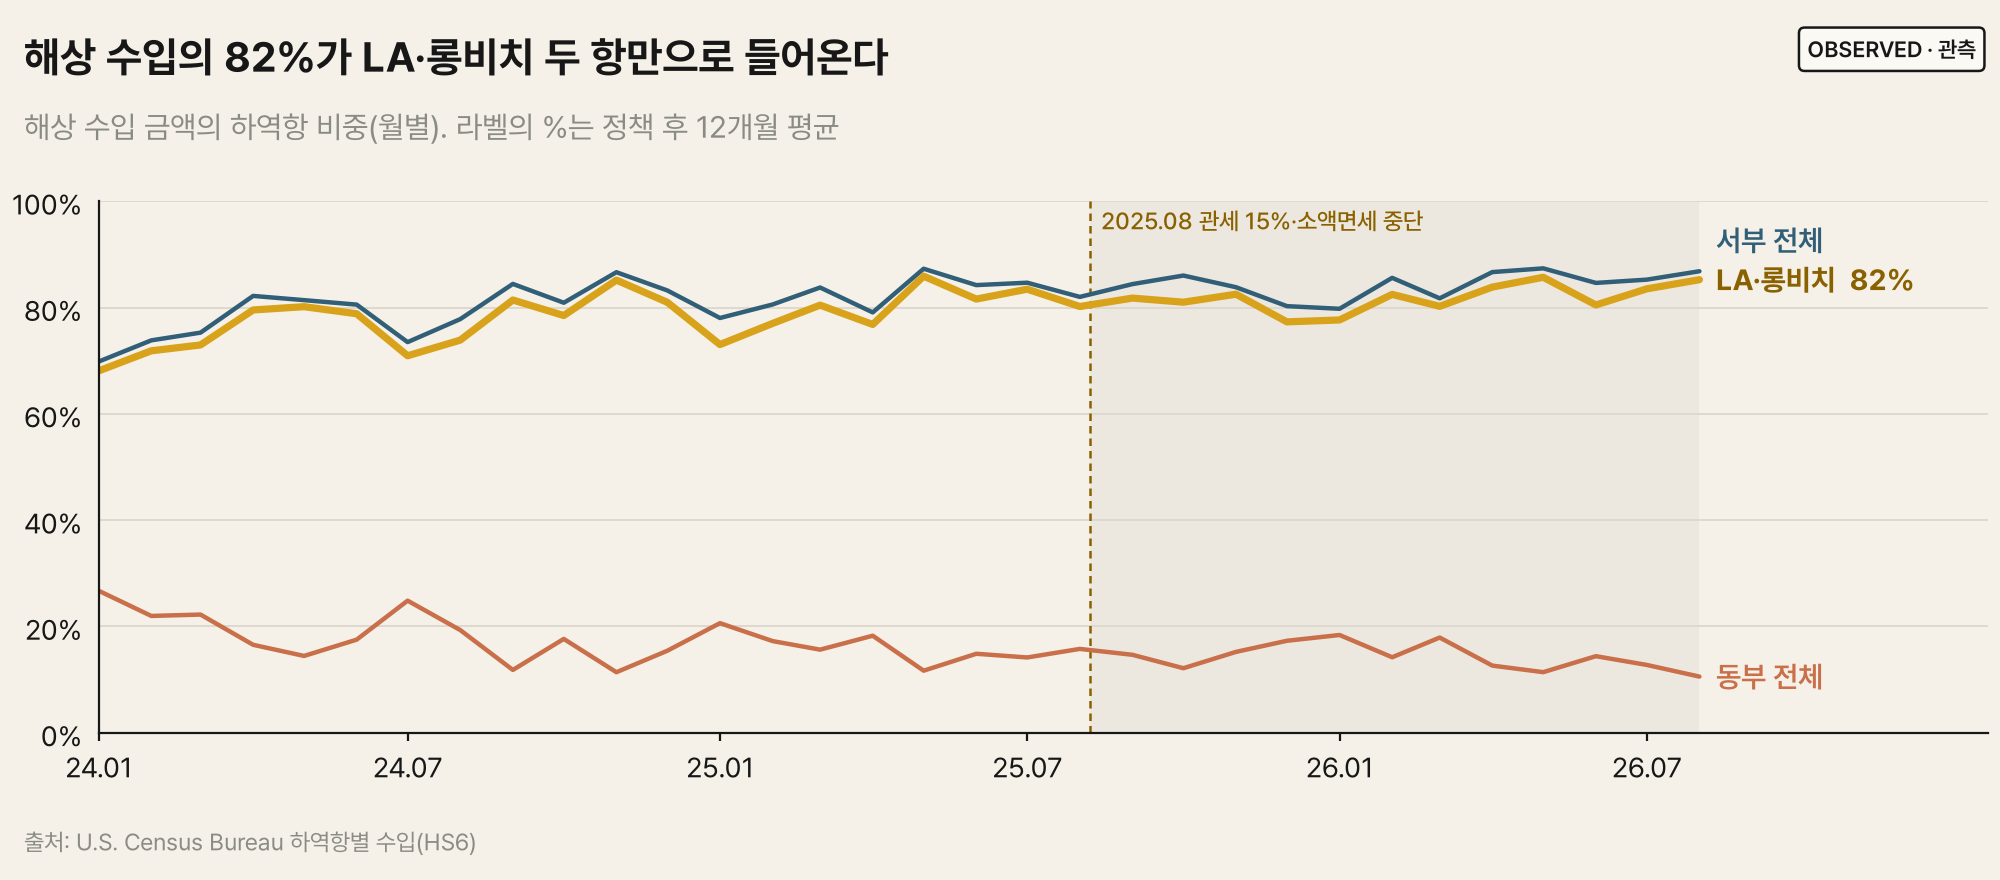

,la_lb_share,west_coast_share,east_coast_share,gulf_coast_share,hhi_vessel
정책 전 12개월,0.804,0.829,0.154,0.016,"5,109.775"
정책 후 12개월,0.818,0.844,0.143,0.013,"5,434.858"


In [2]:
nbviz.show("06_port_concentration")
window = lambda d, w, col="month": d[d[col].between(*w)]
pd.DataFrame({name: window(conc, w)[["la_lb_share", "west_coast_share", "east_coast_share", "gulf_coast_share", "hhi_vessel"]].mean()
              for name, w in (("정책 전 12개월", PRE_WINDOW), ("정책 후 12개월", POST_WINDOW))}).T

**발견**: 해상 수입 금액의 LA·롱비치 비중은 정책 전 12개월 80.4%에서 정책 후 **81.8%로** 조금 올랐다. 서부 전체는 84.4%, 동부는 14.3%, 걸프는 1.3%다.
하역항 HHI는 5,110 → 5,435로, 이미 매우 높은 집중도가 더 높아졌다.

**판단**: K-뷰티 해상 물량의 5분의 4가 두 항구에 걸려 있다. 경로를 고르는 기준(질문 2)과 항만 중단 대비(질문 3)가 실제로 중요한 이유다.

### 1-2. 해상 구간은 얼마나 걸리나 `OBSERVED`

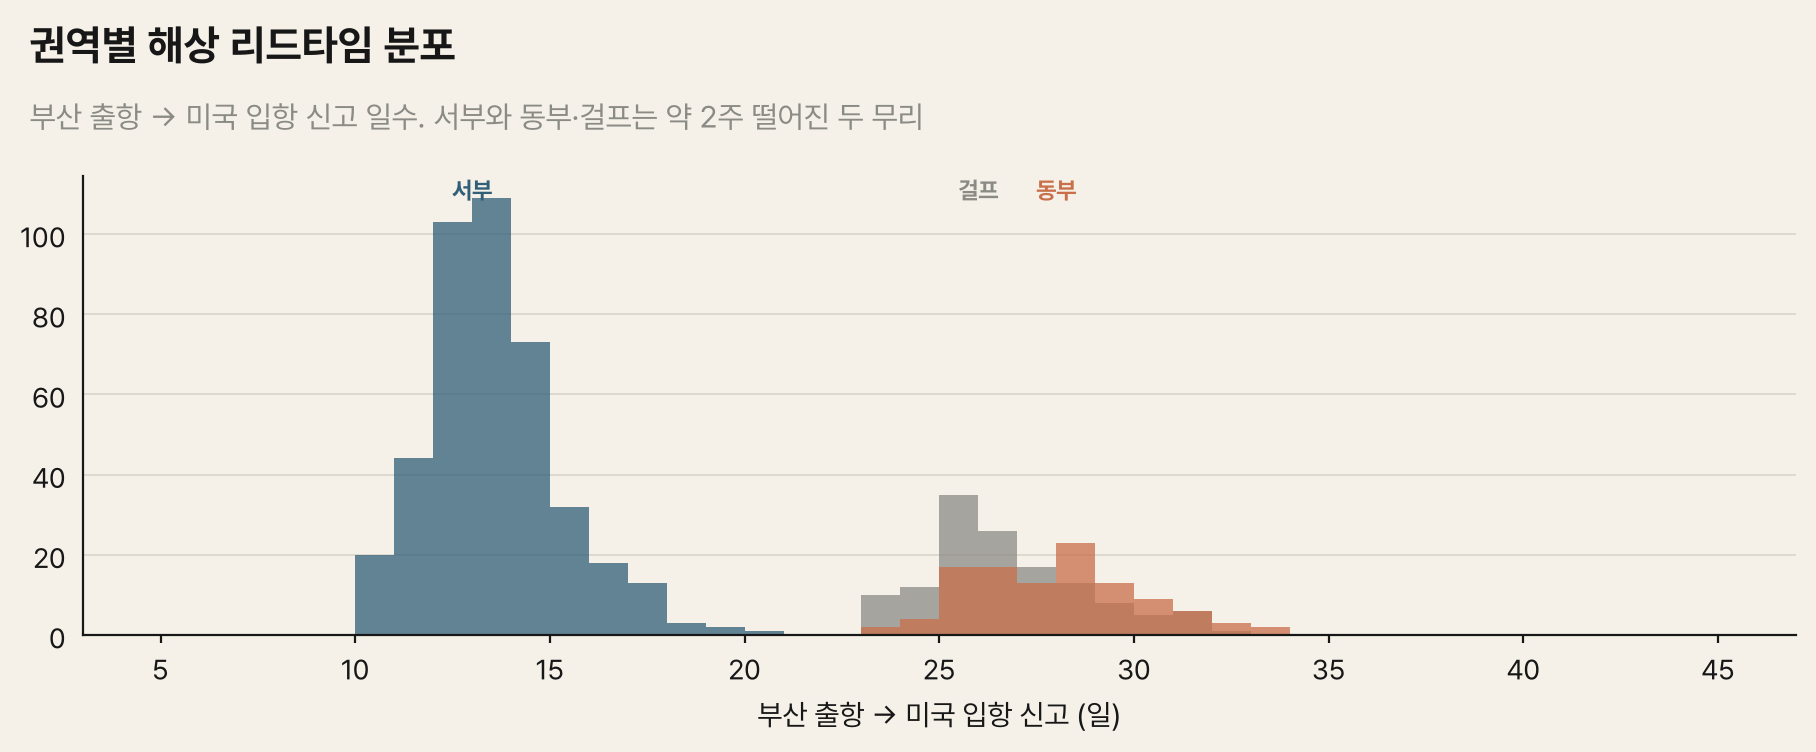

,n,mean,sd,p10,p50,p90
region,,,,,,
west_coast,418,13.062,1.714,11.000,13.000,15.000
gulf_coast,133,26.256,2.080,24.000,26.000,29.000
east_coast,109,27.514,2.201,25.000,28.000,30.200


In [3]:
stats = pd.DataFrame([decision.lead_time_stats(transit, r) for r in REGIONS]).set_index("region")
fig, ax = nbviz.figure(title="권역별 해상 리드타임 분포", subtitle="부산 출항 → 미국 입항 신고 일수. 서부와 동부·걸프는 약 2주 떨어진 두 무리")
for r, c in zip(REGIONS, (C["west"], C["muted"], C["east"])):
    x = transit.loc[transit.region == r, "departure_to_filing_days"]
    ax.hist(x, bins=range(5, 46), alpha=0.75, color=c)
    an.note(ax, x.median(), 1.0, KO[r], coords=("data", "axes fraction"), va="top", ha="center", color=c, weight=700)
ax.set_xlabel("부산 출항 → 미국 입항 신고 (일)")
plt.show()
stats

**발견**: 부산 출항부터 미국 입항 신고까지 평균은 서부 **13.1일**(표준편차 1.7, n = 418), 걸프 26.3일(2.1, n = 133), 동부 **27.5일**(2.2, n = 109)이다.
세 권역 모두 표준편차가 2일 안팎으로 작다. 해상 구간은 길이는 권역마다 크게 다르지만 **흔들림은 작다**.

**판단**: 안전재고 계산에서 해상 구간의 불확실성은 작다. 거점 선택은 주로 **평균 일수 차이(약 14.5일)와** 그 뒤에 붙는 내륙 운송의 길이·변동으로 결정된다.

### 1-3. 정책 후 해상 구간이 달라졌나 `ESTIMATED` (사전 등록 Q5)

판정 기준: 정책 전후 중앙값 차이의 부트스트랩 95% 신뢰구간이 0을 포함하지 않으면 '변화'로 판정한다.

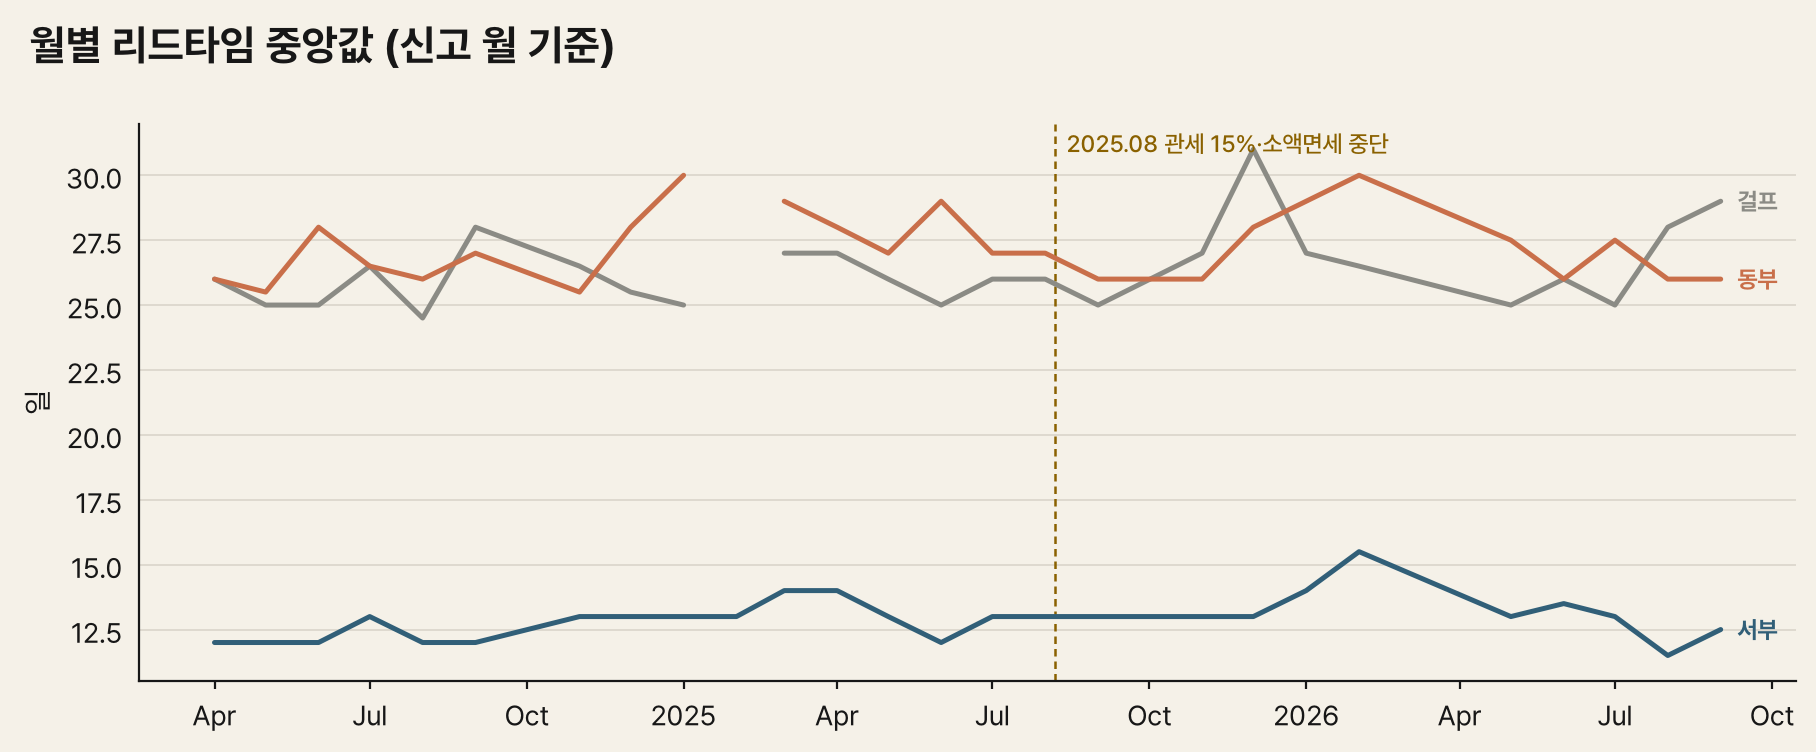

,n_pre,n_post,median_pre,median_post,diff,ci_low,ci_high,sd_pre,sd_post,changed
region,,,,,,,,,,
west_coast,298,120,13.000,13.000,0.000,0.000,0.000,1.716,1.712,False
gulf_coast,100,33,26.000,26.000,0.000,-1.000,1.000,1.921,2.526,False
east_coast,75,34,28.000,27.000,-1.000,-2.000,1.000,2.329,1.896,False


In [4]:
q5 = pd.DataFrame([decision.period_shift(transit, r, POLICY_MONTH) for r in REGIONS]).set_index("region")
monthly = transit.groupby(["filing_month", "region"]).departure_to_filing_days.median().unstack()[REGIONS]
fig, ax = nbviz.figure(title="월별 리드타임 중앙값 (신고 월 기준)")
for r, c in zip(REGIONS, (C["west"], C["muted"], C["east"])):
    ax.plot(monthly.index, monthly[r], color=c, lw=1.8)
    an.note(ax, monthly.index[-1], monthly[r].iloc[-1], KO[r], xytext=(6, 0), color=c, weight=700)
an.policy_marker(ax)
ax.set_ylabel("일")
plt.show()
q5

**발견 (사전 등록 Q5)**:

| 권역 | 정책 전 중앙값 | 정책 후 중앙값 | 차이 | 95% CI | 판정 |
|---|---|---|---|---|---|
| 서부 | 13일 (n = 298) | 13일 (n = 120) | 0 | 0 ~ 0 | 변화 없음 |
| 걸프 | 26일 (n = 100) | 26일 (n = 33) | 0 | −1 ~ 1 | 변화 없음 |
| 동부 | 28일 (n = 75) | 27일 (n = 34) | −1 | −2 ~ 1 | 변화 없음 |

- 서부의 신뢰구간이 0 ~ 0인 것은 관측이 많고 일수가 정수 단위라, 중앙값이 거의 항상 13일로 나오기 때문이다.
- 정책 후 표준편차도 비슷하다(서부 1.72 → 1.71, 동부 2.33 → 1.90). 걸프만 1.92 → 2.53으로 조금 커졌지만 관측이 33건뿐이다.

**판단**: 관세·소액면세 변화는 **해상 운송 시간에는 영향을 주지 않았다.** 03~04 노트북에서 본 변화(물량·신고 단가)는 운송 구간이 아니라 통관·신고 쪽에서 일어난 것으로 보는 것이 일관적이다.

## 질문 2. 어떤 조건에서 선택이 바뀌나 `SCENARIO`

동부 수요를 **동부 직송**(관측된 해상 구간)으로 채울지, **서부 하역 + 내륙 운송**(관측된 서부 해상 구간 + 가정한 내륙 구간)으로 채울지를 묶이는 재고 일수로 비교한다.

$$\text{안전재고(일)} = z \cdot \sqrt{L \cdot CV_d^2 + \sigma_L^2}, \qquad \text{묶이는 재고(일)} = L + \text{안전재고(일)}$$

- 동부 직송: L과 σ_L은 동부 관측치 그대로.
- 서부 하역 + 내륙: L = 서부 관측 평균 + 내륙 일수, σ_L = √(서부 분산 + 내륙 분산).
- **시나리오**(관측 아님): 내륙 일수 5~15일, 내륙 표준편차 2일, 일별 수요 변동계수 CV 0.3/0.5/0.9, 서비스 수준 90/95/99%.
  참고로 LA·롱비치에서 컨테이너가 철도에 실리기까지만 약 4~7일이 걸린다는 보도가 있다. 철도 운송과 최종 배송은 그 위에 더해진다.
- 해상 운임·내륙 운임 등 **비용은 포함하지 않는다.** 재고 일수만 비교한다.

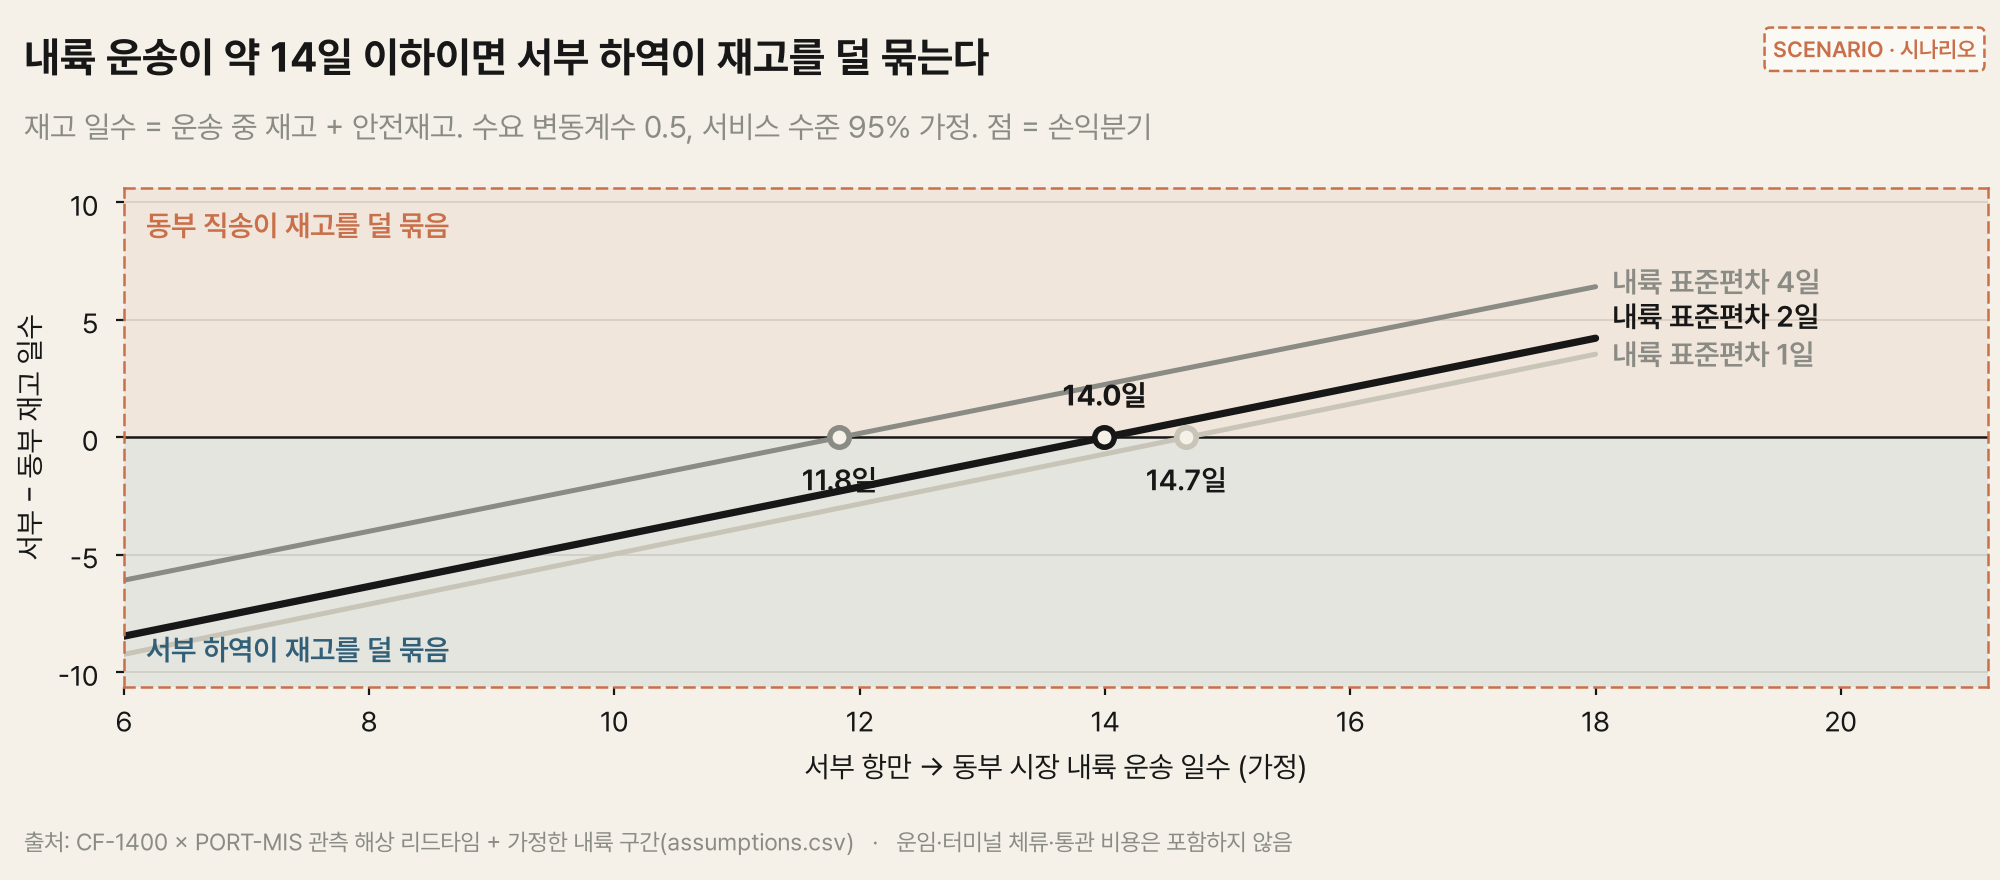

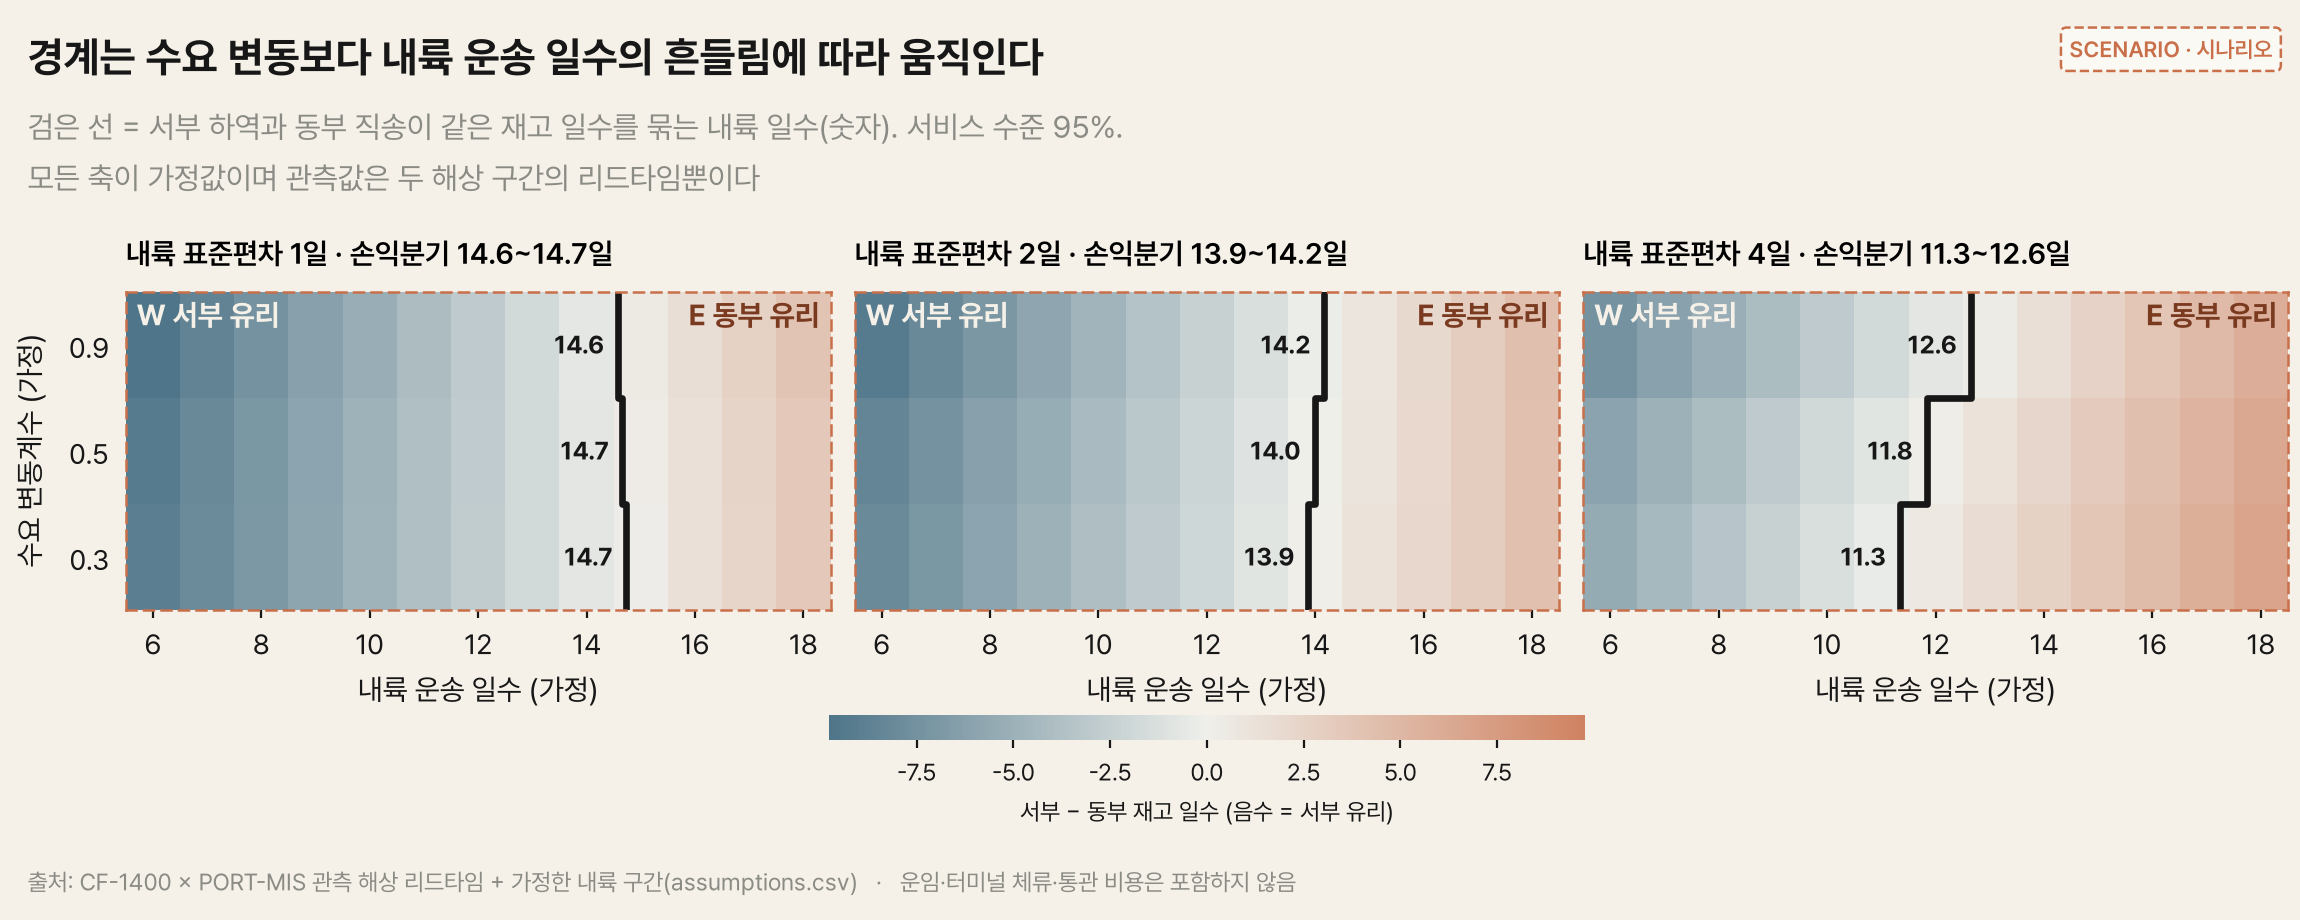

cv_demand,0.300,0.500,0.900
inland_days,,,
5,-9.089,-9.517,-10.380
6,-8.064,-8.457,-9.238
7,-7.039,-7.397,-8.099
8,-6.014,-6.338,-6.962
9,-4.989,-5.279,-5.827
10,-3.964,-4.221,-4.694
11,-2.940,-3.164,-3.563
12,-1.915,-2.107,-2.435
13,-0.891,-1.051,-1.308


In [5]:
east, west = stats.loc["east_coast"].to_dict(), stats.loc["west_coast"].to_dict()
grid = decision.route_comparison(east, west, range(5, 16), INLAND_SD, CV_GRID, SERVICE_LEVELS)
pivot = grid[grid.service_level == 0.95].pivot(index="inland_days", columns="cv_demand", values="west_minus_east_days")
nbviz.show("14_route_breakeven")
nbviz.show("16_route_sensitivity")
pivot

In [6]:
be = pd.DataFrame([{"cv_demand": cv, "service_level": sl, "inland_sd": isd,
                    "break_even_inland_days": decision.break_even_inland_days(east, west, isd, cv, sl)}
                   for cv in CV_GRID for sl in SERVICE_LEVELS for isd in (1.0, INLAND_SD, 4.0)])
be.pivot_table(index=["inland_sd", "service_level"], columns="cv_demand", values="break_even_inland_days")

cv_demand                0.300  0.500  0.900
inland_sd service_level                     
1.000     0.900         14.669 14.617 14.554
          0.950         14.729 14.661 14.580
          0.990         14.839 14.741 14.624
2.000     0.900         13.996 14.092 14.221
          0.950         13.870 13.995 14.163
          0.990         13.637 13.820 14.061
4.000     0.900         12.019 12.393 13.016
          0.950         11.341 11.833 12.647
          0.990         10.081 10.807 11.997

**발견**:
- 서비스 수준 95%, 내륙 표준편차 2일 가정에서 서부 하역 + 내륙 운송이 동부 직송보다 재고를 덜 묶는 조건은 **내륙 운송이 약 14일 이하**일 때다(수요 CV에 따라 13.9~14.2일).
  내륙 5일이면 서부 경로가 9~10일분 재고를 덜 묶고, 15일이면 약 1일분 더 묶는다.
- 손익분기 일수는 사실상 **두 해상 구간의 평균 차이(14.5일)에서** 정해진다. 수요 변동(CV)과 서비스 수준을 바꿔도 0.6일 안에서만 움직인다.
- 그러나 **내륙 운송의 변동에 민감하다.** 내륙 표준편차를 4일로 두면 손익분기 일수가 10.1~13.0일로 줄어든다.
  특히 서비스 수준 99%·수요 CV 0.3(안정 수요를 높은 수준으로 지키는 품목)에서 10.1일까지 내려간다.
  내륙 1일 표준편차라면 14.6~14.8일이다.

**판단**:
- 철도 적재까지만 4~7일이 걸린다는 보도를 감안하면, 서부 하역 + 철도로 동부에 보내는 경로는 손익분기(약 14일) 근처에 있다. **경로 선택은 내륙 운송의 길이보다 '얼마나 일정한가'에 더 좌우될 수 있다.**
- 담당자가 확인할 것은 실제 내륙 운송 업체의 평균 일수와 **일수의 흔들림**이다. 이 두 숫자만 있으면 위 표에서 바로 판단할 수 있다.
- 이 비교는 재고 일수만 본다. 해상·내륙 운임(`NOT MEASURED`), 서부 항만 집중 위험(질문 1·3)은 따로 따져야 한다.

## 질문 3. LA·롱비치 중단에 얼마나 노출돼 있나 `SCENARIO`

하루 평균 해상 수입액(관측) × LA·롱비치 비중(관측) × 중단 일수(가정). 중단 중에도 비중과 일평균 금액이 정책 후 12개월 평균과 같다고 둔다.

In [7]:
disrupt = decision.port_disruption(port_region, conc, POST_WINDOW)
reroute_extra_days = east["mean"] - west["mean"]
disrupt.assign(exposed_musd=lambda d: d.exposed_value_usd / 1e6,
               share_of_annual_sea_value=lambda d: d.exposed_value_usd / (d.vessel_value_per_day_usd * 365))[
    ["closure_days", "la_lb_share", "exposed_musd", "share_of_annual_sea_value"]]

,closure_days,la_lb_share,exposed_musd,share_of_annual_sea_value
0,7,0.818,27.505,0.016
1,14,0.818,55.011,0.031
2,30,0.818,117.880,0.067


In [8]:
print(f"동부 우회 시 해상 구간 추가 일수: 평균 {reroute_extra_days:.1f}일 (동부 {east['mean']:.1f}일 − 서부 {west['mean']:.1f}일)")
for cv in CV_GRID:
    e = decision.route_inventory(east["mean"], east["sd"], cv, 0.95)
    w = decision.route_inventory(west["mean"], west["sd"], cv, 0.95)
    print(f"수요 CV {cv}: 서부 하역(내륙 제외) {w['total_days']:.1f}일 → 동부 우회 {e['total_days']:.1f}일, 추가로 묶이는 재고 {e['total_days'] - w['total_days']:.1f}일분")

동부 우회 시 해상 구간 추가 일수: 평균 14.5일 (동부 27.5일 − 서부 13.1일)
수요 CV 0.3: 서부 하역(내륙 제외) 16.4일 → 동부 우회 32.0일, 추가로 묶이는 재고 15.6일분
수요 CV 0.5: 서부 하역(내륙 제외) 17.2일 → 동부 우회 33.1일, 추가로 묶이는 재고 16.0일분
수요 CV 0.9: 서부 하역(내륙 제외) 19.1일 → 동부 우회 36.1일, 추가로 묶이는 재고 17.0일분


**발견**: 정책 후 12개월 기준 하루 평균 해상 수입액은 약 480만 달러이고, 그중 81.8%가 LA·롱비치로 들어온다.

| LA·롱비치 중단 | 영향 받는 해상 수입액 | 연간 해상 수입액 대비 |
|---|---|---|
| 7일 | 2,750만 달러 | 1.6% |
| 14일 | 5,500만 달러 | 3.1% |
| 30일 | 1억 1,790만 달러 | 6.7% |

동부로 돌리면 해상 구간이 평균 14.5일 길어진다. 서비스 수준 95%에서 묶이는 재고가 15.6~17.0일분 늘어난다(수요 CV 0.3~0.9, 내륙 운송 제외).

**판단**: 2주 중단이면 연간 해상 물량의 3%가 지연된다. 동부 우회는 재고를 2주 넘게 더 묶는다. 서부 집중을 유지한다면 **성수기 전 서부 창고 안전재고를 2주분 이상** 확보하는 것이 이 데이터가 주는 기준선이다.
금액은 미국 측 신고 가격 기준이며(04 노트북), 판매액이 아니다.

## 결론: 담당자를 위한 판단 기준

| 질문 | 이 데이터가 주는 답 | 근거 수준 |
|---|---|---|
| 1. 어디로 들여오나 | 해상 수입 금액의 **82%가 LA·롱비치**. 해상 구간은 서부 13일, 동부 28일로 14.5일 차이 | `OBSERVED` |
| 1. 정책 영향 | 정책 후 해상 리드타임은 **변하지 않았다**(사전 등록 Q5, 세 권역 모두 CI가 0 포함) | `ESTIMATED` |
| 2. 언제 바꾸나 | 내륙 운송이 **약 14일 이하이면 서부 경유가 재고를 덜 묶는다**. 내륙 일수가 들쑥날쑥하면(표준편차 4일) 기준이 10~13일로 짧아진다 | `SCENARIO` |
| 3. 얼마나 노출돼 있나 | LA·롱비치 2주 중단 = 해상 수입 5,500만 달러(연간의 3%) 지연. 동부 우회 시 재고 15.6~17.0일분 추가 | `OBSERVED` 비중 + `SCENARIO` 중단 |
| 안전재고 크기 | 해상 구간 변동은 작다(표준편차 약 2일). 안전재고는 **수요 변동과 내륙 변동**에 좌우된다. 05 노트북 결과대로 예측 구간이 실제보다 좁으므로 한 단계 높은 서비스 수준으로 계산한다 | `OBSERVED` + `ESTIMATED` |
| 비용 | 해상·내륙 운임, 터미널 체류, 통관 시간, 재고 유지 비용 | `NOT MEASURED` |

### 한계
- 리드타임은 '부산 출항 → 미국 입항 신고'까지다. 터미널 체류, 통관, 내륙 배송은 관측하지 않았다(체류시간 자료는 수집했지만 이 분석에 쓰지 않음).
- 내륙 운송 일수·변동, 수요 변동, 서비스 수준은 시나리오다. 실제 판단에는 운송 업체 실적과 자사 판매 데이터가 필요하다.
- 운임과 재고 유지 비용은 포함하지 않았다. 재고 일수 비교는 비용 비교의 출발점일 뿐이다.
- 선박 관측치는 선박 단위다. 특정 브랜드 화물이 어느 배에 실렸는지는 알 수 없다.

---

## 부록: 일치 확인

노트북의 Q5·손익분기·항만 노출 결과가 `scripts/run_all.py`의 표와 같은지 확인한다.

In [9]:
s_q5 = pd.read_csv(TABLES_DIR / "decision_q5_shift.csv").set_index("region")
assert np.allclose(s_q5.loc[REGIONS, ["median_pre", "median_post", "ci_low", "ci_high"]], q5.loc[REGIONS, ["median_pre", "median_post", "ci_low", "ci_high"]])
s_be = pd.read_csv(TABLES_DIR / "decision_breakeven.csv")
mine = be[be.inland_sd == INLAND_SD].merge(s_be, on=["cv_demand", "service_level"], suffixes=("_nb", "_saved"))
assert np.allclose(mine.break_even_inland_days_nb, mine.break_even_inland_days_saved)
s_dis = pd.read_csv(TABLES_DIR / "decision_port_disruption.csv")
assert np.allclose(s_dis.exposed_value_usd, disrupt.exposed_value_usd)
print("notebook results match reports/tables/decision_*.csv")

notebook results match reports/tables/decision_*.csv
